# 4.2: diseño del filtro pasabanda del ECG

**Qué hace el filtro.** Saca la deriva lenta de la línea de base (movimientos, respiración, contacto de los electrodos) y el ruido de alta frecuencia, sin deformar el QRS, que es de donde salen los picos R (RR) y el área del QRS (EDR). Se aplica **ida y vuelta** (`sosfiltfilt`): la fase total es cero, así que no corre el pico R, y la ganancia efectiva es |H(f)|², o sea, en decibeles, el doble de la de una pasada.

**Reglas (fijadas antes de correr; no usan etiquetas de apnea).**
1. **Límite inferior de la banda de paso: f_FC,min**, la frecuencia cardíaca más baja de desarrollo (percentil 1 del ritmo instantáneo, en Hz). Por debajo está la deriva; por encima, la fundamental del latido, que no conviene atenuar.
2. **Límite superior de la banda de paso: f_QRS**, la frecuencia por debajo de la cual queda el 99 % de la energía del latido mediano, tomando el percentil 95 entre los registros de desarrollo.
3. **Especificación con el filtrado ida y vuelta:** atenuación de 1 dB o menos en [f_FC,min, f_QRS], y de 20 dB o más a 0,1 Hz (deriva lenta).
4. **Candidatos:** Butterworth con corte bajo de 0,3, 0,5 o 0,7 Hz, corte alto de 35, 40 o 45 Hz, y orden de 1 a 6.
5. **Elección:** si el filtro usado hasta ahora (0,5–40 Hz, orden 2, el de E1 a E3b) cumple la especificación, se mantiene. Si no, gana el de menor orden que la cumple y, a igual orden, el de cortes más cercanos a los anteriores.
6. **Verificación**, solo si cambia el filtro: F (AUC por minuto y acierto por registro) con el filtro nuevo contra el anterior, no inferioridad con δ = 0,02. Y E1 como control, porque el EDR por área usa este filtro.

In [1]:
import sys
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import ECG_FILTER, RESULTS_DIR, SPLIT_CSV
from src.data import load_ecg, load_qrs
from src.features.edr import qrs_reference
from src.preprocessing.filters import (apply_zero_phase, beat_spectrum, cumulative_energy_freq,
                                       design_bandpass, frequency_response, mean_psd, meets_spec)
from src.qrs.pan_tompkins import r_peaks_from_marks
from src.qrs.rr_clean import clean_rr

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
FS = 100.0
PREVIO = (0.5, 40.0, 2)          # filtro usado hasta E3b, antes de esta etapa
print("filtro anterior:", PREVIO, "| filtro en config:", ECG_FILTER, "|", len(DEV), "registros de desarrollo")

filtro anterior: (0.5, 40.0, 2) | filtro en config: (0.5, 45.0, 3) | 47 registros de desarrollo


In [2]:
ecgs, f99, fc = {}, [], []
for rec in DEV:
    ecg, fs = load_ecg(rec)
    ecgs[rec] = ecg
    qrs = load_qrs(rec)
    off, sign = qrs_reference(ecg, qrs, fs)
    peaks = np.rint(r_peaks_from_marks(ecg, qrs, fs, off, sign)[0] * fs).astype(int)
    f, p = beat_spectrum(ecg, peaks, fs)
    f99.append(cumulative_energy_freq(f, p, 0.99))
    _, rr, corr = clean_rr(peaks / fs)
    fc.append(1 / rr[~corr])
fc = np.concatenate(fc)
F_FC_MIN = float(np.percentile(fc, 1))
F_QRS = float(np.percentile(f99, 95))
print(f"frecuencia cardíaca: percentil 1 = {F_FC_MIN:.2f} Hz ({60 * F_FC_MIN:.0f} lpm), mediana {np.median(fc):.2f} Hz")
print(f"99 % de la energía del latido: mediana {np.median(f99):.1f} Hz, percentil 95 = {F_QRS:.1f} Hz (máx {max(f99):.1f})")
print(f"-> banda de paso a respetar: {F_FC_MIN:.2f} a {F_QRS:.1f} Hz")

frecuencia cardíaca: percentil 1 = 0.77 Hz (46 lpm), mediana 1.15 Hz
99 % de la energía del latido: mediana 29.1 Hz, percentil 95 = 41.8 Hz (máx 45.8)
-> banda de paso a respetar: 0.77 a 41.8 Hz


energía < 0,5 Hz: 23.6% | 0,5-42 Hz: 66.3% | > 42 Hz: 10.05%


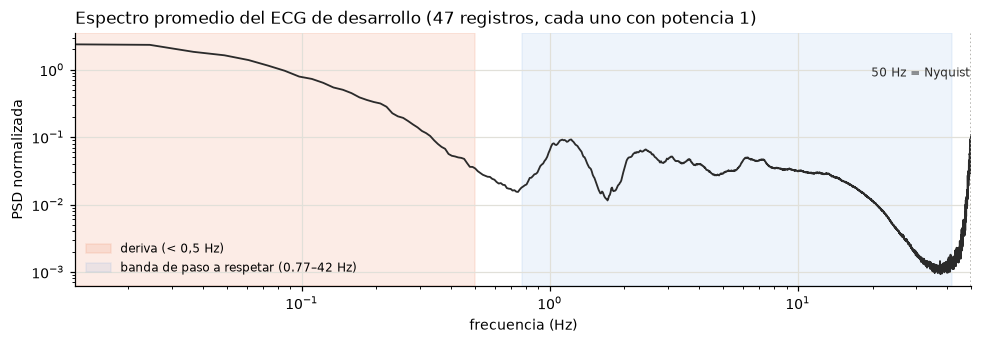

In [3]:
f, psd = mean_psd(list(ecgs.values()), FS, nperseg=8192)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.semilogy(f[1:], psd[1:], color=TINTA, lw=1.2)
ax.axvspan(f[1], 0.5, color=NARANJA, alpha=0.12, label="deriva (< 0,5 Hz)")
ax.axvspan(F_FC_MIN, F_QRS, color=AZUL, alpha=0.08, label=f"banda de paso a respetar ({F_FC_MIN:.2f}–{F_QRS:.0f} Hz)")
ax.axvline(50, color=GRIS, lw=1, ls=":")
ax.text(49.5, psd[1:].max() / 3, "50 Hz = Nyquist", ha="right", fontsize=8, color=TINTA)
ax.set_xscale("log"); ax.set_xlim(f[1], 50)
ax.set_xlabel("frecuencia (Hz)"); ax.set_ylabel("PSD normalizada")
ax.set_title("Espectro promedio del ECG de desarrollo (47 registros, cada uno con potencia 1)", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "filtro_espectro.png")
fr = lambda a, b: np.trapezoid(psd[(f >= a) & (f < b)], f[(f >= a) & (f < b)])
print(f"energía < 0,5 Hz: {fr(0, 0.5):.1%} | 0,5-{F_QRS:.0f} Hz: {fr(0.5, F_QRS):.1%} | > {F_QRS:.0f} Hz: {fr(F_QRS, 50.01):.2%}")

In [4]:
filas = []
for low, high, order in product((0.3, 0.5, 0.7), (35, 40, 45), range(1, 7)):
    sos = design_bandpass(FS, low, high, order)
    filas.append({"corte bajo": low, "corte alto": high, "orden": order,
                  "cumple": meets_spec(sos, FS, (F_FC_MIN, F_QRS), {0.1: 20}, max_pass_db=1)})
cand = pd.DataFrame(filas)
previo_cumple = bool(cand.query("`corte bajo` == @PREVIO[0] and `corte alto` == @PREVIO[1] and orden == @PREVIO[2]").cumple.iloc[0])
if previo_cumple:
    ELEGIDO = PREVIO
else:
    ok = cand[cand.cumple].copy()
    ok["distancia"] = (ok["corte bajo"] - PREVIO[0]).abs() + (ok["corte alto"] - PREVIO[1]).abs() / 10
    ELEGIDO = tuple(ok.sort_values(["orden", "distancia"]).iloc[0][["corte bajo", "corte alto", "orden"]])
    ELEGIDO = (float(ELEGIDO[0]), float(ELEGIDO[1]), int(ELEGIDO[2]))
print(f"¿el filtro anterior cumple la especificación? {previo_cumple} -> filtro elegido: {ELEGIDO}")
for nombre, p in (("anterior", PREVIO), ("elegido", ELEGIDO)):
    r = frequency_response(design_bandpass(FS, *p), FS, n=2 ** 16)
    g = {f0: r["ganancia_db_ida_vuelta"][np.argmin(np.abs(r["f"] - f0))] for f0 in (0.1, F_FC_MIN, F_QRS)}
    print(f"  {nombre} {p}: ida y vuelta {g[0.1]:.1f} dB a 0,1 Hz | {g[F_FC_MIN]:.2f} dB a {F_FC_MIN:.2f} Hz | {g[F_QRS]:.2f} dB a {F_QRS:.1f} Hz")
cand.pivot_table(index=["corte bajo", "corte alto"], columns="orden", values="cumple")

¿el filtro anterior cumple la especificación? False -> filtro elegido: (0.5, 45.0, 3)
  anterior (0.5, 40.0, 2): ida y vuelta -56.1 dB a 0,1 Hz | -1.39 dB a 0.77 Hz | -10.41 dB a 41.8 Hz
  elegido (0.5, 45.0, 3): ida y vuelta -84.0 dB a 0,1 Hz | -0.62 dB a 0.77 Hz | -0.39 dB a 41.8 Hz


orden                    1    2    3    4    5    6
corte bajo corte alto                              
0.3        35          0.0  0.0  0.0  0.0  0.0  0.0
           40          0.0  0.0  0.0  0.0  0.0  0.0
           45          0.0  0.0  1.0  1.0  1.0  1.0
0.5        35          0.0  0.0  0.0  0.0  0.0  0.0
           40          0.0  0.0  0.0  0.0  0.0  0.0
           45          0.0  0.0  1.0  1.0  1.0  1.0
0.7        35          0.0  0.0  0.0  0.0  0.0  0.0
           40          0.0  0.0  0.0  0.0  0.0  0.0
           45          0.0  0.0  0.0  0.0  0.0  0.0

retardo de una pasada en 10-20 Hz: 2.9 ms (una muestra = 10 ms) | ganancia en 50 Hz: -175 dB


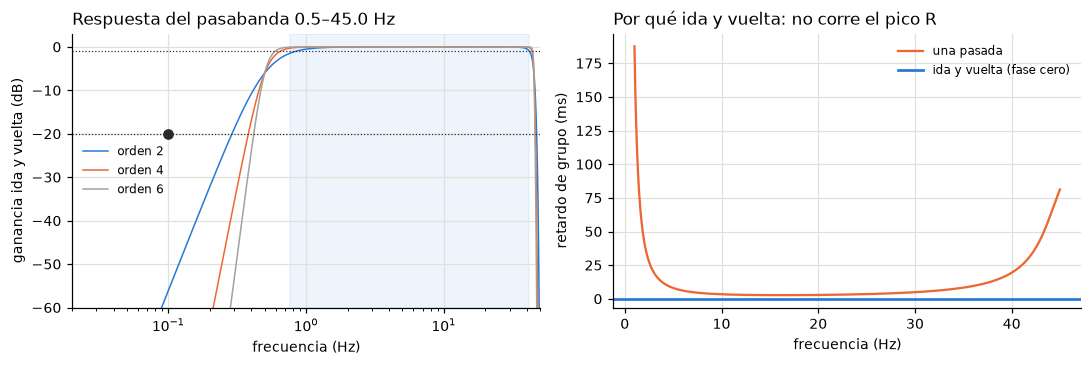

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
for order, color in ((2, AZUL), (4, NARANJA), (6, GRIS)):
    r = frequency_response(design_bandpass(FS, ELEGIDO[0], ELEGIDO[1], order), FS)
    a1.semilogx(r["f"][1:], r["ganancia_db_ida_vuelta"][1:], color=color, lw=1.8 if order == ELEGIDO[2] else 1,
                label=f"orden {order}" + (" (elegido)" if order == ELEGIDO[2] else ""))
a1.axvspan(F_FC_MIN, F_QRS, color=AZUL, alpha=0.08)
a1.axhline(-1, color=TINTA, lw=0.8, ls=":"); a1.axhline(-20, color=TINTA, lw=0.8, ls=":")
a1.scatter([0.1], [-20], color=TINTA, zorder=3)
a1.set_ylim(-60, 3); a1.set_xlim(0.02, 50)
a1.set_xlabel("frecuencia (Hz)"); a1.set_ylabel("ganancia ida y vuelta (dB)")
a1.set_title(f"Respuesta del pasabanda {ELEGIDO[0]}–{ELEGIDO[1]} Hz", loc="left")
a1.legend(frameon=False, fontsize=8)
r = frequency_response(design_bandpass(FS, *ELEGIDO), FS)
sel = (r["f"] >= 1) & (r["f"] <= 45)
a2.plot(r["f"][sel], 1000 * r["retardo_s"][sel], color=NARANJA, lw=1.5, label="una pasada")
a2.axhline(0, color=AZUL, lw=1.8, label="ida y vuelta (fase cero)")
a2.set_xlabel("frecuencia (Hz)"); a2.set_ylabel("retardo de grupo (ms)")
a2.set_title("Por qué ida y vuelta: no corre el pico R", loc="left"); a2.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "filtro_respuesta.png")
print(f"retardo de una pasada en 10-20 Hz: {1000 * r['retardo_s'][(r['f'] >= 10) & (r['f'] <= 20)].mean():.1f} ms "
      f"(una muestra = 10 ms) | ganancia en 50 Hz: {r['ganancia_db'][-1]:.0f} dB")

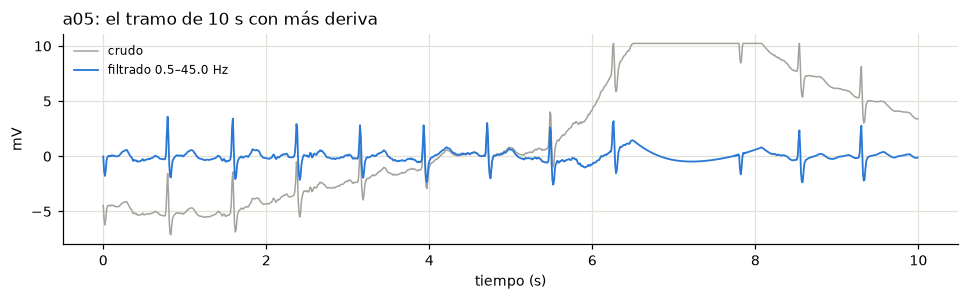

In [6]:
# Ejemplo: el tramo de 10 s con más deriva entre unos pocos registros de desarrollo (elegido por regla)
best = None
for rec in DEV[:10]:
    x = ecgs[rec]
    lento = apply_zero_phase(x, design_bandpass(FS, 0.05, 0.5, 2))
    n = 1000
    var = pd.Series(lento[: len(x) // n * n].reshape(-1, n).std(axis=1))
    i = int(var.idxmax())
    if best is None or var[i] > best[2]:
        best = (rec, i * n, var[i])
rec, i0, _ = best
x = ecgs[rec][i0:i0 + 1000]
y = apply_zero_phase(ecgs[rec], design_bandpass(FS, *ELEGIDO))[i0:i0 + 1000]
t = np.arange(1000) / FS
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(t, x, color=GRIS, lw=1, label="crudo")
ax.plot(t, y, color=AZUL, lw=1.2, label=f"filtrado {ELEGIDO[0]}–{ELEGIDO[1]} Hz")
ax.set_xlabel("tiempo (s)"); ax.set_ylabel("mV")
ax.set_title(f"{rec}: el tramo de 10 s con más deriva", loc="left"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "filtro_ejemplo.png")

## Verificación (solo si el filtro cambia)

Se recalcula F (la configuración final de E3b: potencia cruzada RR–EDR, 0,01–0,05 Hz, 240 s, Welch, EDR por área) con el filtro elegido y con el anterior, sobre los mismos minutos de evaluación de E3a. Se adopta el nuevo si es no inferior en las dos medidas (límite inferior del IC 95 % de la diferencia ≥ −0,02). Control: la métrica de E1 (coherencia entre el EDR por área y la respiración real) en los 8 registros con respiración.

In [7]:
import os
from concurrent.futures import ProcessPoolExecutor
os.environ["PYTHONPATH"] = str(ROOT)
from src.features.build import record_minute_table
from src.features.variants import coupling_variants, hrv_variants
from src.stats.compare import agreement_compare, compare_variants

if ELEGIDO == PREVIO:
    print("El filtro no cambia: no hace falta verificar.")
else:
    CACHE = RESULTS_DIR / "e3"
    coup = pd.read_parquet(CACHE / "acoplamiento.parquet"); hrv = pd.read_parquet(CACHE / "hrv.parquet")
    wc, _ = coupling_variants(coup); wh, _ = hrv_variants(hrv)
    info = (coup[(coup.edr == "area") & (coup.window == 512) & (coup.estimator == "welch3")]
            .set_index(["record", "minute"])[["label", "corrected"]])
    idx = wc.dropna().index.intersection(wh.dropna().index).intersection(
        info.index[(info.label >= 0) & (info.corrected <= 0.2)])
    y = info.loc[idx, "label"].to_numpy().astype(int)
    recs = idx.get_level_values("record").to_numpy(); subj = split.loc[recs, "subject"].to_numpy()
    del coup, wc
    B = {"ap": (0.01, 0.05)}
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1)) as ex:
        tabs = {nombre: pd.concat(ex.map(record_minute_table, DEV, [240] * len(DEV), [B] * len(DEV),
                                         [ROOT / "data" / "raw"] * len(DEV), [None] * len(DEV),
                                         ["area"] * len(DEV), ["welch3"] * len(DEV), [filt] * len(DEV)))
                       .set_index(["record", "minute"])
                for nombre, filt in (("anterior", PREVIO), ("nuevo", ELEGIDO))}
    F = pd.DataFrame({f"F con filtro {n}": np.log(np.maximum(t.loc[idx, "xp_ap"], 1e-12)) for n, t in tabs.items()})
    print(f"minutos: {len(idx):,} | F con filtro anterior reproduce E3b: AUC "
          f"{compare_variants(F, y, subj, n_boot=10).auc.iloc[0]:.3f}")
    auc_v = compare_variants(F, y, subj, n_boot=2000)
    agr_v = agreement_compare(F, y, recs, subj, n_boot=2000)
    display(auc_v[["auc", "ic_lo", "ic_hi", "dif", "dif_lo", "dif_hi"]].round(3))
    display(agr_v.round(3))

minutos: 22,123 | F con filtro anterior reproduce E3b: AUC 0.876


,auc,ic_lo,ic_hi,dif,dif_lo,dif_hi
F con filtro anterior,0.876,0.811,0.925,0.000,0.000,0.0
F con filtro nuevo,0.875,0.809,0.925,-0.001,-0.002,-0.0


,spearman,ic_lo,ic_hi,dif,dif_lo,dif_hi,empata
F con filtro anterior,0.813,0.557,0.935,0.000,0.000,0.000,True
F con filtro nuevo,0.810,0.556,0.935,-0.003,-0.018,0.004,True


In [8]:
if ELEGIDO != PREVIO:
    from src.config import RESP_RECORDS
    from src.data import load_respiration
    from src.features.coupling import downsample, resample_uniform
    from src.features.edr import compute_edr, validate_edr
    filas = []
    for rec in RESP_RECORDS:
        ecg = ecgs[rec]; qrs = load_qrs(rec)
        resp, fr = load_respiration(rec)
        r2 = {c: downsample(resp[c], fr, 2.0) for c in ("Resp C", "Resp A", "Resp N")}
        fila = {"registro": rec}
        for nombre, filt in (("anterior", PREVIO), ("nuevo", ELEGIDO)):
            tu, vu = resample_uniform(*compute_edr(ecg, qrs, FS, "area", filt), 2.0)
            idx_r = np.rint(tu * 2).astype(int)
            vals = []
            for c, s in r2.items():
                ok = idx_r < len(s)
                vals.append(np.nanmedian(validate_edr(vu[ok], s[idx_r[ok]], 2.0)))
            fila[nombre] = np.mean(vals)
        filas.append(fila)
    e1 = pd.DataFrame(filas).set_index("registro")
    d = (e1.nuevo - e1.anterior).to_numpy()
    boot = np.random.default_rng(2026).choice(d, size=(5000, len(d))).mean(axis=1)
    print(f"E1 (coherencia EDR-respiración): anterior {e1.anterior.mean():.3f} | nuevo {e1.nuevo.mean():.3f} | "
          f"diferencia {d.mean():+.3f} (IC {np.percentile(boot, 2.5):+.3f} a {np.percentile(boot, 97.5):+.3f})")
    display(e1.round(3))

E1 (coherencia EDR-respiración): anterior 0.531 | nuevo 0.520 | diferencia -0.011 (IC -0.030 a +0.002)


,anterior,nuevo
registro,,
a01,0.515,0.512
a02,0.348,0.339
a03,0.456,0.457
a04,0.315,0.321
b01,0.620,0.630
c01,0.703,0.631
c02,0.531,0.522
c03,0.759,0.751


In [9]:
if ELEGIDO != PREVIO:
    DELTA = 0.02
    def dif_nuevo(t, col):
        # La tabla da diferencias contra la mejor columna; se pasa a (nuevo - anterior).
        a, n = "F con filtro anterior", "F con filtro nuevo"
        if t.loc[a, "dif"] == 0:
            return t.loc[n, col] - t.loc[a, col], t.loc[n, "dif_lo"], t.loc[n, "dif_hi"]
        return t.loc[n, col] - t.loc[a, col], -t.loc[a, "dif_hi"], -t.loc[a, "dif_lo"]
    crit = pd.DataFrame({m: dict(zip(("diferencia", "ic_lo", "ic_hi"), dif_nuevo(t, c)))
                         for m, t, c in (("AUC por minuto", auc_v, "auc"), ("acierto por registro", agr_v, "spearman"))}).T
    crit["no inferior"] = crit.ic_lo >= -DELTA
    display(crit.round(3))
    ADOPTA = bool(crit["no inferior"].all())
    FINAL = ELEGIDO if ADOPTA else PREVIO
else:
    FINAL = PREVIO
print("filtro que queda:", FINAL, "| config.ECG_FILTER:", ECG_FILTER,
      "-> coincide" if tuple(ECG_FILTER) == tuple(FINAL) else "-> NO coincide: actualizar config")

,diferencia,ic_lo,ic_hi,no inferior
AUC por minuto,-0.001,-0.002,-0.000,True
acierto por registro,-0.003,-0.018,0.004,True


filtro que queda: (0.5, 45.0, 3) | config.ECG_FILTER: (0.5, 45.0, 3) -> coincide


## Decisión

**Se adopta el pasabanda Butterworth 0,5–45 Hz, orden 3, ida y vuelta** (`config.ECG_FILTER = (0.5, 45.0, 3)`). Afecta a los dos caminos: el pico R refinado (RR) y el área del QRS (EDR).

- **Por qué cambia.** La especificación sale de los datos de desarrollo, sin etiquetas: el ritmo más bajo es 0,77 Hz (46 lpm) y el 99 % de la energía del latido queda por debajo de 41,8 Hz. El filtro anterior (0,5–40 Hz, orden 2) no la cumple: con la ida y vuelta atenúa 10,4 dB a 41,8 Hz y 1,4 dB a 0,77 Hz. El elegido atenúa 0,4 y 0,6 dB, y 84 dB a 0,1 Hz. Es el de menor orden que cumple; con corte alto de 35 o 40 Hz no cumple ningún orden.
- **Verificación (no inferioridad, δ = 0,02).** AUC por minuto de F: 0,876 → 0,875, diferencia −0,001 (IC −0,002 a −0,000). Acierto por registro: Spearman 0,813 → 0,810, diferencia −0,003 (IC −0,018 a +0,004). Las dos cumplen. El cambio tampoco mejora F: la diferencia es de milésimas.
- **Control E1** (coherencia EDR–respiración, 8 registros): 0,531 → 0,520, diferencia −0,011 (IC −0,030 a +0,002). No es significativa, pero con 8 registros el IC es ancho y su límite pasa −0,02: no se puede afirmar que sea no inferior en E1. Casi todo viene de c01 (0,703 → 0,631); los otros 7 cambian 0,010 o menos. E1 era un control, no el criterio fijado: se reporta y no cambia la decisión.
- **Qué implica.** El cambio corrige el filtro para que respete la banda del QRS medida en los datos; no es una mejora de rendimiento. Las conclusiones de E1 a E3b se mantienen, porque F casi no cambia. Los notebooks 02 a 06 quedan como se ejecutaron (filtro anterior, caché en `results/e3`); si se recalculan sin la caché usan el filtro nuevo y sus números pueden moverse en el orden de esta verificación.